## Script for Exercise 3 ("Risk-based grid operation") 

Intro script for Exercise 3 in specialization course module 
"Flexibility in power grid operation and planning" at NTNU (TET4565/TET4575) 

In [117]:
# Dependencies

import os
import pandas as pd
import load_profiles as lp
import pandapower_read_csv as ppcsv
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

In [118]:
# Define input data

# Location of (processed) data set for CINELDI MV reference system
# (to be replaced by your own local data folder)
path_data_set         = 'C:/Users/Eier/OneDrive - NTNU/9. Semester/Fordypningsemne, Kraftmarkeder/Module 1, Flexibility/7703070'

filename_load_data_fullpath = os.path.join(path_data_set,'load_data_CINELDI_MV_reference_system.csv')
filename_load_mapping_fullpath = os.path.join(path_data_set,'mapping_loads_to_CINELDI_MV_reference_grid.csv')
filename_standard_overhead_lines = os.path.join(path_data_set,'standard_overhead_line_types.csv')
filename_reldata = os.path.join(path_data_set,'reldata_for_component_types.csv')
filename_load_point = os.path.join(path_data_set,'CINELDI_MV_reference_system_load_point.csv')

# Subset of load buses to consider in the grid area, considering the area at the end of the main radial in the grid
bus_i_subset = [90, 91, 92, 96]

# Factor to scale the loads for this exercise compared with the base version of the CINELDI reference system data set
scaling_factor = 10

# Read standard component reliability data
data_comp_rel = pd.read_csv(filename_reldata, delimiter=';')
data_comp_rel.set_index(keys = 'main_type', drop = True, inplace = True)

# Read load point data (incl. specific rates of costs of energy not supplied) for data
data_load_point = pd.read_csv(filename_load_point, delimiter=';')
data_load_point.set_index(keys = 'bus_i', drop = True, inplace = True)

In [119]:
# Read pandapower network

net = ppcsv.read_net_from_csv(path_data_set, baseMVA=10)

c:\Users\Eier\OneDrive - NTNU\9. Semester\Fordypningsemne, Kraftmarkeder\Module 1, Flexibility\CINELDI_MV_reference_system-flexibility_course_NTNU_public\pandapower_read_csv.py:123: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_bus = pd.concat([res_bus, res_row])


In [120]:
# Set up hourly normalized load time series for a representative day

load_profiles = lp.load_profiles(filename_load_data_fullpath)

# Consider only the day with the peak load in the area (28 February)
repr_days = [31+28]

# Get relative load profiles for representative days mapped to buses of the CINELDI test network;
# the column index is the bus number (1-indexed) and the row index is the hour of the year (0-indexed)
profiles_mapped = load_profiles.map_rel_load_profiles(filename_load_mapping_fullpath,repr_days)

# Calculate load time series in units MW (or, equivalently, MWh/h) by scaling the normalized load time series by the
# maximum load value for each of the load points in the grid data set (in units MW); the column index is the bus number
# (1-indexed) and the row index is the hour of the year (0-indexed)
load_time_series_mapped = profiles_mapped.mul(net.load['p_mw'])

# Aggregated load time series for the subset of load buses
load_time_series_subset = load_time_series_mapped[bus_i_subset] * scaling_factor
load_time_series_subset_aggr = load_time_series_subset.sum(axis=1)

c:\Users\Eier\OneDrive - NTNU\9. Semester\Fordypningsemne, Kraftmarkeder\Module 1, Flexibility\CINELDI_MV_reference_system-flexibility_course_NTNU_public\load_profiles.py:46: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  loaddata.index = pd.to_datetime([d + " " + "%.2d" % (int(t) - 1) for d, t in timestamp_list], dayfirst=True)
c:\Users\Eier\OneDrive - NTNU\9. Semester\Fordypningsemne, Kraftmarkeder\Module 1, Flexibility\CINELDI_MV_reference_system-flexibility_course_NTNU_public\load_profiles.py:87: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  profile_days = pd.concat([profile_days, profile_day])
c:\Users\Eier\OneDrive - NTNU\9. Se

In [121]:
#Task 1: Estimate the annual expected energy not supplied for the grid
#Expected energy not supplied (EENS) = lambda * r * P

length_MF = 20 #length of main feeder [km]
P_avg = 1.841 #average load demand throghout the year. 

lambda_perm = data_comp_rel['lambda_perm'].iloc[0] # failure rate, overhead line [failures per 100 km per year]
r_perm = data_comp_rel['r_perm'].iloc[0]# outage time per failure [h per failure]

lambda_MF = lambda_perm * length_MF / 100# failure rate of main feeder. 
EENS = lambda_MF * r_perm * P_avg

print('lambda =', lambda_MF, 'failures/year')
print('EENS =', EENS, 'MWh/year')

lambda = 0.794 failures/year
EENS = 4.385262 MWh/year


In [122]:
#Task 2: Estimate the annual expected cost of energy not supplied for the grid

#From the article: "It is also assumed that expected annual interruption costs for a load point will be calculated by multiplying
#the annual expected energy not supplied (ENS) measured in kWh for the load point by some
#specific interruption cost cENS in units NOK/kWh (cost level 2021). """

#CENS   = sum (c_i * EENS_i for i in bus_i_subset)
#Formulas: EENS_i = lambda * r * P_i for in in bus_i_subset

# Finding the average load per bus 
# Weighted load: P_i = P_avg * (P_max_i / sum(P_max)) #assuming equal relationship between the loads throghtout the whole year. 
P_max = net.load.loc[bus_i_subset, 'p_mw'] # peak load per bus (from the data set)
weight= P_max / P_max.sum()
P_i = P_avg * weight

# c_i: Average specific interruption cost per bus [NOK/kWh], r = 3 h closest to 4 h, so using the 4h column
c_i = data_load_point.loc[bus_i_subset, 'c_NOK_per_kWh_4h']

EENS_i = lambda_MF * r_perm * P_i #[MWh/year]

# CENS = sum_i c_i * EENS_i [NOK/year]
# Multiply by 1000 to convert EENS from MWh to kWh, since c_i is given in NOK/kWh
CENS = (c_i * EENS_i * 1000).sum()

print('P_avg_check =', round(P_i.sum(), 3), 'MW')    # checking that: should be about 1.841
print('CENS =', round(CENS), 'NOK/year')

P_avg_check = 1.841 MW
CENS = 237221 NOK/year


In [123]:
#Task 3: Estimate the annual expected cost of energy not supplied for the grid with a battery

P_cap_bat =1 # battery power capacity [MW]
E_cap_bat = 2 # battery energy capacity [MWh].During a 3 h outage the battery could give 1 MW * 3 h = 3 MWh, but it only stores 2 MWh. The energy capacity is the limit. 

# EENS for the whole area [MWh/year]
# Same as Task 1, but the battery energy is subtracted
EENS_bat = lambda_MF * (r_perm * P_avg - E_cap_bat)

# CENS for the whole area [NOK/year]
# The battery supplies the whole area, so its energy is split between the buses. Using the same load weight as in Task 2.
EENS_i_bat = lambda_MF * (r_perm * P_i - E_cap_bat * weight)
CENS_bat = (c_i * EENS_i_bat * 1000).sum()

print('EENS with battery =', EENS_bat, 'MWh/year')
print('CENS with battery =', CENS_bat, 'NOK/year')

EENS with battery = 2.797262 MWh/year
CENS with battery = 151318.1862519747 NOK/year


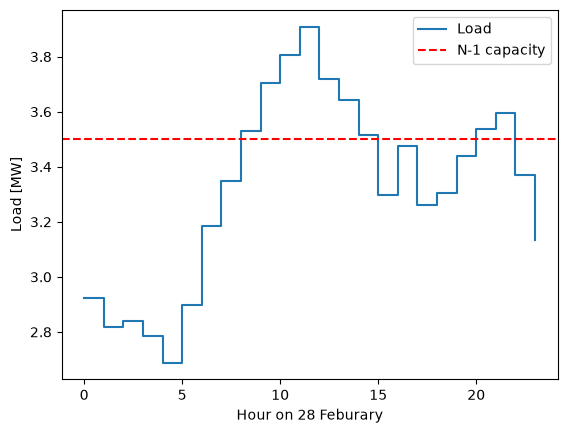

CENS_d = 21.392882066521324 NOK/day


In [124]:
#Task 4: Estimate the daily expected cost of energy not supplied for the grid with a backup feeder

P_backup_feeder = 3.5 # backup feeder capacity [MW]
P_h = load_time_series_subset_aggr.values # load each hour on 28 February [MW]

# Plot load and N-1 capacity
plt.step(range(24),P_h,where='post', label='Load')
plt.axhline(P_backup_feeder, color='r', linestyle='--', label='N-1 capacity')
plt.xlabel('Hour on 28 Feburary')
plt.ylabel('Load [MW]')
plt.legend()
plt.show()

P_above_h = np.maximum(0, P_h - P_backup_feeder) #saves amount over 3.5 MW every hour of the day  

lambda_h = lambda_MF / 8760 # need failure rate per hour, not year 
EENS_h = lambda_h * r_perm * P_above_h #EENS for each hour [MWh]
EENS_d = EENS_h.sum() # EENS of the day [MWh/day]

EENS_i_d = EENS_d * weight #EENS per bus, split by same load share as before [MWh/day]

CENS_d = (c_i * EENS_i_d * 1000).sum() #CENS for the day [NOK/day]

print('CENS_d =', CENS_d, 'NOK/day')

E_cap = 2 MWh: lowest SoC = 0.6762018937167538 MWh -> possible: True
E_cap = 1.4 MWh: lowest SoC = 0.07620189371675368 MWh -> possible: True
E_cap = 1.0 MWh: lowest SoC = -0.32379810628324623 MWh -> possible: False


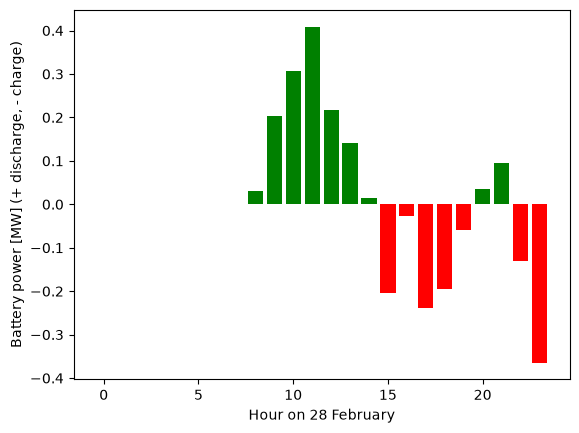

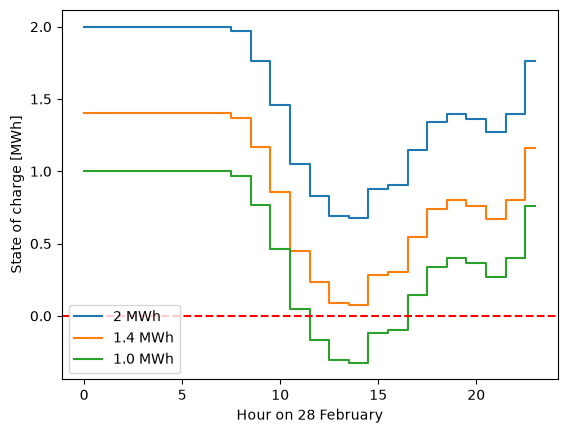

In [125]:
#Task 5:  Schedule battery dispatch for day-ahead operational planning to satisfy the N-1 criterion

P_bat_dict = {} # battery power for each battery size [MW]
SoC_dict = {}# state of charge for each battery size [MWh]

P_cap_bat = 1# battery power capacity [MW]

for E_cap in [2, 1.4, 1.0]:# battery sizes [MWh]
    SoC = E_cap # full battery at the start of the day
    P_bat = [] # battery power each hour (+ discharge, - charge) [MW]
    SoC_list = [] # state of charge each hour [MWh]

    for P in P_h:
        if P > P_backup_feeder:
            p = P - P_backup_feeder# discharge the load above 3.5 MW
        else:
            p = -min(P_cap_bat, P_backup_feeder - P, E_cap - SoC) # charge as much as possible, limited by battery power, free capacity below 3.5 MW from backup feeder, and the space left in the battery
        SoC = SoC - p
        P_bat.append(p)
        SoC_list.append(SoC)

    P_bat_dict[E_cap] = P_bat # save results for this battery size
    SoC_dict[E_cap] = SoC_list

    print(f'E_cap = {E_cap} MWh: lowest SoC = {min(SoC_list)} MWh -> possible: {min(SoC_list) >= 0}')


# Figure 1: charge/discharge
for E_cap in P_bat_dict:
    P_bat = P_bat_dict[E_cap]
    colors = ['green' if p > 0 else 'red' for p in P_bat]# green = discharge, red = charge
    plt.bar(range(24), P_bat, color=colors)
plt.xlabel('Hour on 28 February')
plt.ylabel('Battery power [MW] (+ discharge, - charge)')
plt.show()

# Figure 2: state of charge
for E_cap in SoC_dict:
    plt.step(range(24), SoC_dict[E_cap], where='mid', label=f'{E_cap} MWh')
plt.axhline(0, color='r', linestyle='--')      # empty battery
plt.xlabel('Hour on 28 February')
plt.ylabel('State of charge [MWh]')
plt.legend()
plt.show()

In [126]:
#Task 6: Estimate operational costs of flexibility procurement for the next day
# Formula: C_flex = price_flex * E_shifted

price_flex = 2000 # price for energy shifted [NOK/MWh]

E_shifted = P_above_h.sum()#energy discharged by the battery = load above 3.5 MW [MWh]
C_flex = price_flex * E_shifted # total cost of flexibility for the day [NOK/day]

print('Energy shifted =', E_shifted, 'MWh')
print('Flexibility cost =', C_flex, 'NOK/day')

Energy shifted = 1.4543658375138868 MWh
Flexibility cost = 2908.7316750277737 NOK/day


In [127]:
#Task 7: Discuss which operational strategy is most cost-effective

# Interruption cost if a failure actually occurs in the peak hour, do not include probability beacuse we assume it actually happens

P_above_max = P_above_h.max()# highest load above 3.5 MW during the day [MW]
EENS = r_perm * P_above_max# energy not supplied for this one failure [MWh]
ENS_i = EENS * weight  # EENS per bus, split by load share [MWh]
CENS_peak = (c_i * ENS_i * 1000).sum()# interruption cost of this failure [NOK]

print('Interruption cost for a failure in the peak hour =', CENS_peak, 'NOK')

Interruption cost for a failure in the peak hour = 66353.44625546929 NOK


In [ ]:
#Task 8: How might weather forecast change the operational planning?

k = C_flex / CENS_d # how many times larger the failure rate must be
lambda_new = k * lambda_MF # new break-even failure rate [failures/year]

lambda_d = lambda_new / 365 # failure rate per day [failures/day]
p_d = lambda_d # approx probability of failure during the day

print('Factor k =', k)
print('Break-even failure rate =', lambda_new, 'failures/year')
print('Probability of failure next day =', p_d * 100, '%')

Factor k = 135.9672654662916
Break-even failure rate = 107.95800878023553 failures/year
Probability of failure next day = 29.577536652119324 %


In [ ]:
# Task 9: How do the properties of the flexibility resource affect the realism of strategy (i)

P_EWH = 2 # power of EWH [kW]
E_EWH = 1.17 # energy capacity EWH[kWh]
share_on = 9 / 100 # # and at most 9 of 100 EWHs were heating at the same time

P_needed = P_above_h.max() * 1000# largest load reduction needed (peak hour) [kW]
n_on = P_needed / P_EWH # number of EWHs that must be heating and switched off
n_total = n_on / share_on# total number of EWHs needed, since only 9 % are heating

print('Load reduction needed =', P_needed, 'kW')
print('Total EWHs needed =', n_total)


Load reduction needed = 408.8690601282443 kW
Total EWHs needed = 2271.494778490246
